# Concrete Compressive Strength — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [UCI Machine Learning Repository — Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete-compressive-strength)

Each row is one concrete mixture tested in the lab: the amounts of seven ingredients, the age of the sample when tested, and the measured compressive strength.

| Column | Description | Units |
|---|---|---|
| `cement` | Cement | kg per m³ of mixture |
| `blast_furnace_slag` | Blast furnace slag | kg/m³ |
| `fly_ash` | Fly ash | kg/m³ |
| `water` | Water | kg/m³ |
| `superplasticizer` | Superplasticizer | kg/m³ |
| `coarse_aggregate` | Coarse aggregate | kg/m³ |
| `fine_aggregate` | Fine aggregate | kg/m³ |
| `age_days` | Age at testing | days |
| `strength_mpa` | Compressive strength | MPa |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the data (internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [1]:
from pathlib import Path
import io, zipfile
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
ZIP_PATH = DATA / 'concrete_uci165.zip'
URL = 'https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip'

if not ZIP_PATH.is_file():
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    ZIP_PATH.write_bytes(r.content)

with zipfile.ZipFile(ZIP_PATH) as z:
    df = pd.read_excel(io.BytesIO(z.read('Concrete_Data.xls')))

df.columns = ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer',
              'coarse_aggregate', 'fine_aggregate', 'age_days', 'strength_mpa']
print(df.shape)
df.head()

(1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age_days,strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
blast_furnace_slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
fly_ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
coarse_aggregate,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
fine_aggregate,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
age_days,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
strength_mpa,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


## 2. A first look

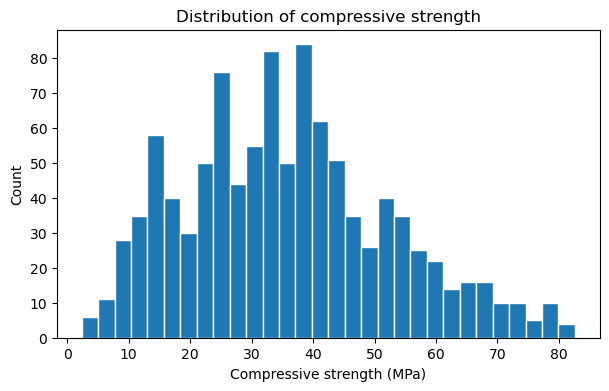

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['strength_mpa'], bins=30, edgecolor='white')
ax.set(xlabel='Compressive strength (MPa)', ylabel='Count', title='Distribution of compressive strength')
plt.show()

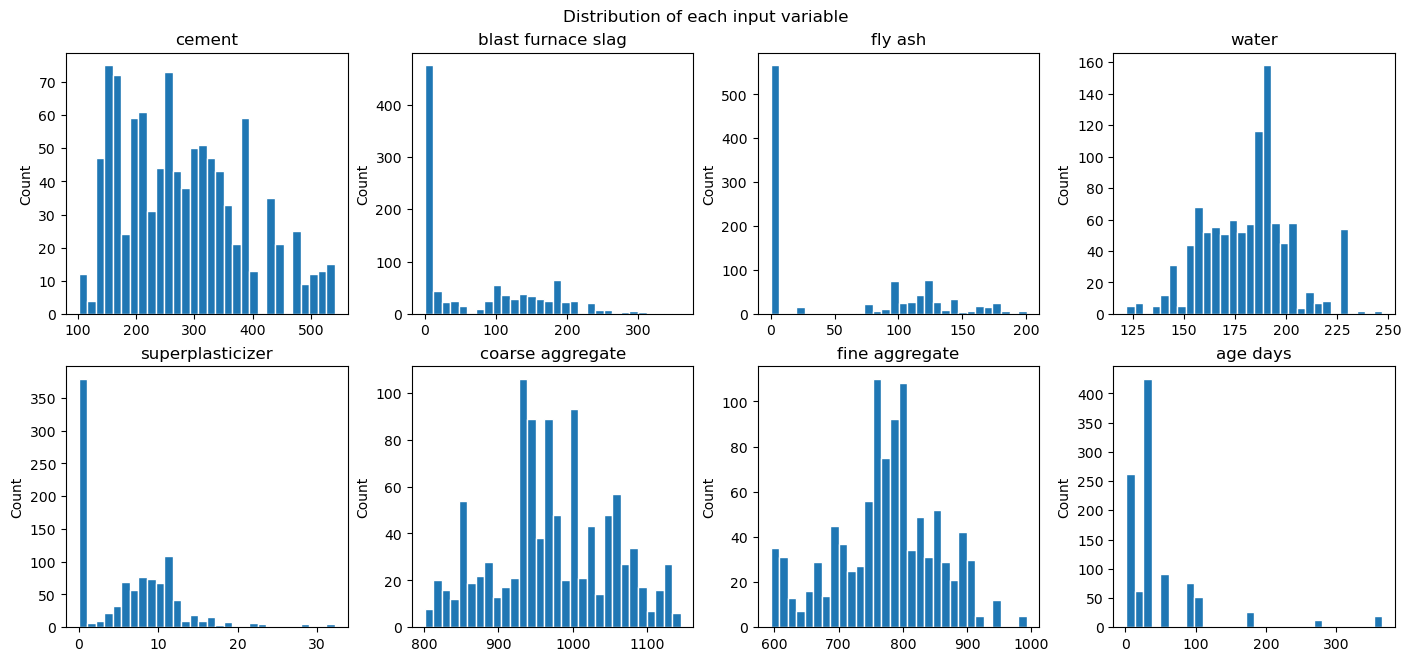

In [4]:
inputs = df.columns.drop('strength_mpa')
fig, axs = plt.subplots(2, 4, figsize=(14, 6.5), constrained_layout=True)
for ax, col in zip(axs.flat, inputs):
    ax.hist(df[col], bins=30, edgecolor='white')
    ax.set(title=col.replace('_', ' '), ylabel='Count')
fig.suptitle('Distribution of each input variable')
plt.show()

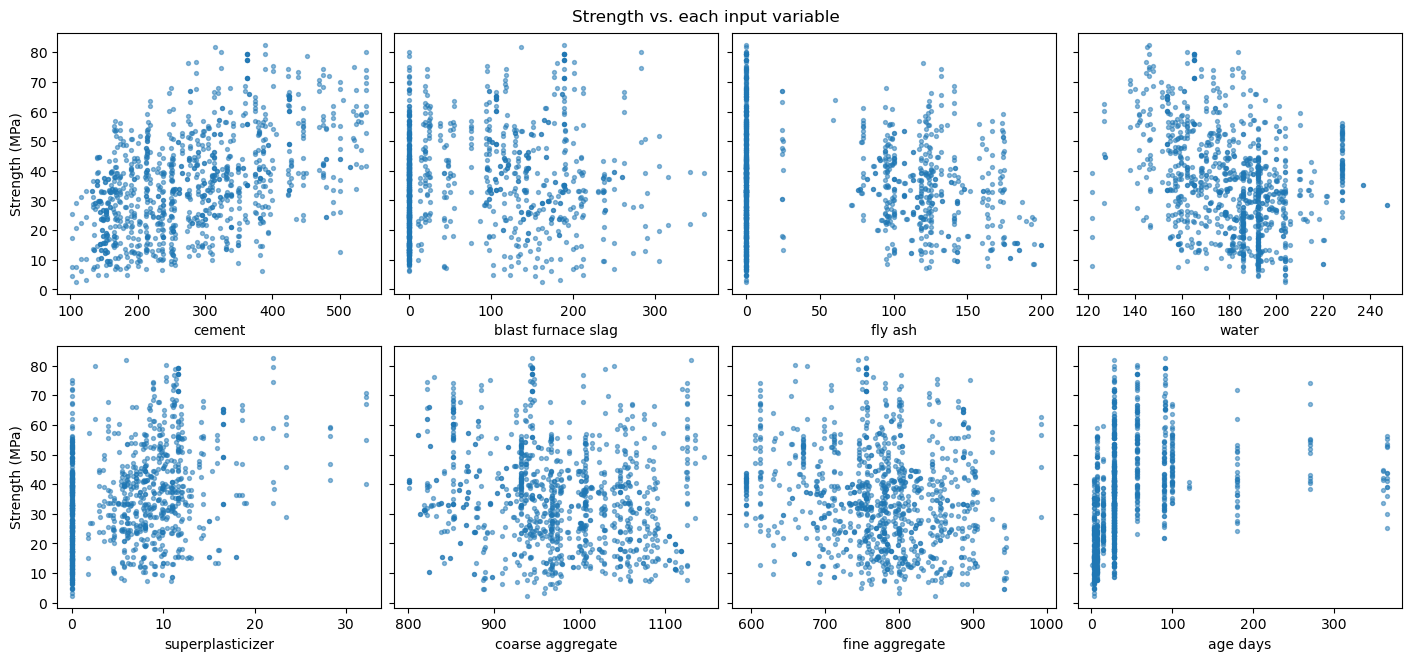

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6.5), sharey=True, constrained_layout=True)
for ax, col in zip(axs.flat, inputs):
    ax.scatter(df[col], df['strength_mpa'], s=8, alpha=0.5)
    ax.set(xlabel=col.replace('_', ' '))
for ax in axs[:, 0]:
    ax.set_ylabel('Strength (MPa)')
fig.suptitle('Strength vs. each input variable')
plt.show()

## 3. Your exploration
Add your own analysis below.